# Who gets the credit for a film's return?

The other notebooks ask what predicts a film's return. This one asks how the return splits up: how much goes
with the budget, the genre and the franchise, how much with each director, actor, writer, producer, studio and
distributor, and how much is left over. It's an optional extra: nothing else in the repo depends on it.

It reads the saved outputs of `python -m analysis.attribution.run` and needs no raw data.
[`docs/profit-attribution.md`](../docs/profit-attribution.md) has the method and its limits in full.

Sections:
1. Three ways to measure profit, and how far they agree
2. The model
3. How much goes with each role
4. Is it more than noise?
5. The people and companies
6. One film, split into dollars
7. What could be known before release
8. Summary

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

REPO = Path.cwd().resolve().parents[1]   # notebooks -> repo root
SRC = REPO / "archive" / "analysis" / "attribution" / "outputs"
S = json.loads((SRC / "summary.json").read_text())
films = pd.read_csv(SRC / "films.csv")
ent = pd.read_csv(SRC / "entities.csv")
fe = pd.read_csv(SRC / "film_entities.csv.gz")

INK, ACCENT, GREY, LIGHT, RED = "#1F2933", "#0072B2", "#8A969C", "#D5E3E8", "#D55E00"
CONTROLS = ["budget", "year", "genre", "franchise"]
ROLES = list(S["penalties"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.3f}".format

def usd(v):
    a = abs(v)
    return ("-" if v < 0 else "") + (f"${a / 1e9:,.2f}B" if a >= 1e9 else f"${a / 1e6:,.1f}M")

print(f"{S['sample']['films']:,} clean films, {S['sample']['years'][0]} to {S['sample']['years'][1]}; "
      f"{S['sample']['franchise_films']:,} in a franchise; mean ln(gross / budget) {S['outcome']['mean']:.3f}, sd {S['outcome']['sd']:.3f}")

6,413 clean films, 1975 to 2025; 1,736 in a franchise; mean ln(gross / budget) 0.569, sd 1.414


## 1. Three ways to measure profit

We don't have real profit for any film. What we have is the budget and the worldwide gross, and two things are
missing between them: cinemas keep part of the gross, and the budget leaves out marketing. So there are three
measures to choose from, and none is right:

- **Gross ÷ budget**, the multiple. It doesn't depend on inflation or on the size of the film, and it favours
  cheap films: a horror film made for very little can gross a hundred times its budget.
- **Gross − budget** in dollars. It favours big films, and it counts all of the gross as the studio's.
- **Share × gross − budget**, an estimated profit, where the share stands for what's left after the cinemas' cut.
  The share isn't published film by film, so it's an assumption. Below it's set to three values to see how much
  the answer moves. Marketing is still missing from all three.

The model in the next sections uses the first, in logs. The dollar figures later are splits of the gross, which
you can scale by whichever share you believe.

In [2]:
sc = pd.DataFrame(S["measures"]["scenarios"]).T
sc.index.name = "share of gross kept"
print(f"Median gross / budget: {S['measures']['median_multiple']:.2f}. Grossed less than budget: {S['measures']['share_gross_under_budget']:.1%}.")
sc[["break_even_multiple", "share_of_films_above_break_even", "median_usd", "total_usd",
    "share_of_all_gains_from_top_decile_of_films", "spearman_with_multiple", "top_decile_overlap_with_multiple"]]

Median gross / budget: 2.07. Grossed less than budget: 28.0%.


,break_even_multiple,share_of_films_above_break_even,median_usd,total_usd,share_of_all_gains_from_top_decile_of_films,spearman_with_multiple,top_decile_overlap_with_multiple
share of gross kept,,,,,,,
0.4,2.500,0.427,"-1,900,000.000","37,678,391,729.864",0.742,0.838,0.410
0.5,2.000,0.513,"350,000.000","106,106,017,367.830",0.692,0.861,0.368
0.6,1.667,0.576,"3,100,000.000","174,533,643,005.796",0.659,0.862,0.337


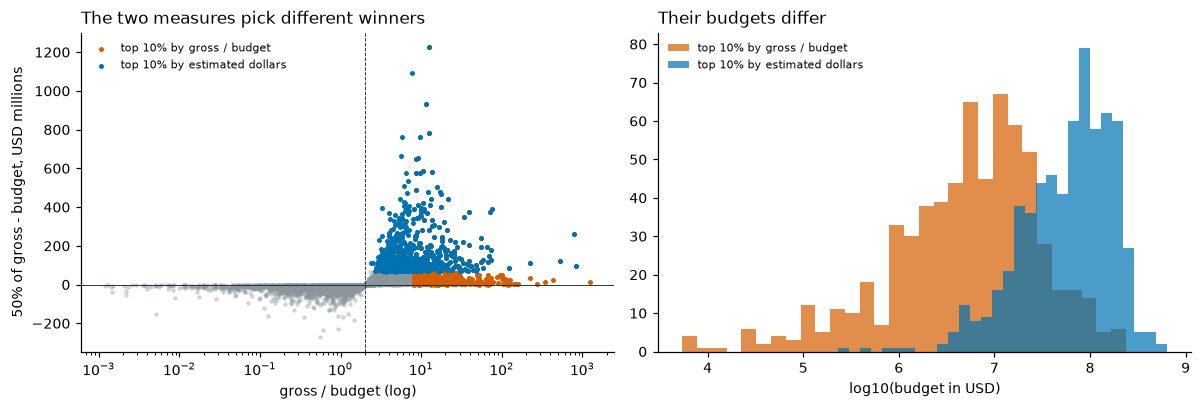

At a 50% share: 37% of the top tenth by multiple is also in the top tenth by dollars. Median budget $6.0M against $71.5M.


In [3]:
share = 0.5
est = share * films.gross_usd - films.budget_usd
mult = films.gross_usd / films.budget_usd
k = len(films) // 10
top_m, top_e = mult.nlargest(k).index, est.nlargest(k).index
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(mult, est / 1e6, s=4, alpha=.3, color=GREY)
axes[0].scatter(mult[top_m], est[top_m] / 1e6, s=5, color=RED, label="top 10% by gross / budget")
axes[0].scatter(mult[top_e], est[top_e] / 1e6, s=5, color=ACCENT, label="top 10% by estimated dollars")
axes[0].set_xscale("log"); axes[0].axhline(0, color=INK, lw=.6); axes[0].axvline(1 / share, color=INK, lw=.6, ls="--")
axes[0].set_xlabel("gross / budget (log)"); axes[0].set_ylabel(f"{share:.0%} of gross - budget, USD millions")
axes[0].set_title("The two measures pick different winners", loc="left"); axes[0].legend(frameon=False, fontsize=7)
axes[1].hist(np.log10(films.budget_usd[top_m]), bins=30, alpha=.7, color=RED, label="top 10% by gross / budget")
axes[1].hist(np.log10(films.budget_usd[top_e]), bins=30, alpha=.7, color=ACCENT, label="top 10% by estimated dollars")
axes[1].set_xlabel("log10(budget in USD)"); axes[1].set_title("Their budgets differ", loc="left"); axes[1].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()
print(f"At a {share:.0%} share: {len(set(top_m) & set(top_e)) / k:.0%} of the top tenth by multiple is also in the top tenth by dollars. "
      f"Median budget {usd(films.budget_usd[top_m].median())} against {usd(films.budget_usd[top_e].median())}.")

The two measures agree on the order of most films (the rank correlation in the table) and disagree on the
winners: the top tenth by multiple is mostly cheap films, and the top tenth by dollars is mostly expensive ones. A
few films earn most of the gains (the top-decile column). Which measure the paper uses is still an open decision,
and this is what it changes.

## 2. The model

A film's ln(gross / budget) is written as a sum of parts:

> intercept + budget + year + genre + franchise + an effect for every person and company on it + what's left

The people are the director, the three top-billed actors, the writers, producers, composer, cinematographer and
editor. The companies are the producing studios and the distributors. Anyone with at least two films in the
sample gets an effect, and all the effects are fitted at once, so an actor's effect is what remains of their
films' returns after the director, the studio, the budget and everyone else have taken their part.

Three things keep it honest:

- **Shrinkage.** Each effect is pulled towards zero, more so when there are few films behind it (ridge
  regression, one penalty per role, chosen by cross-validation). Sports analysts call the same model adjusted
  plus-minus. A role whose chosen penalty is large is one where the data can't tell individuals apart.
- **Out of fold.** When a film's return is split, the effects used are fitted without that film and without
  the other films of its franchise. A film can't explain itself.
- **Logs.** Effects multiply: +0.10 means the film grosses exp(0.10), about 1.105 times, what it would with an
  average person in that seat.

What it measures: who goes with high returns once everyone else on the film is accounted for. What it misses:
why. People aren't put on films at random. A star is offered better projects, a big distributor picks films it
expects to sell and gives them a wide release, and none of that is in the model, so it lands in their effect.

In [4]:
pen = pd.DataFrame({"penalty": S["penalties"], "with an effect": S["sample"]["entities_with_an_effect"],
                    "films with at least one": S["sample"]["films_with_at_least_one"], "sd of effects": S["effect_sd"]})
pen.index.name = "role"
print(f"Cross-validated R2 ({S['cv']['folds']} folds, franchises kept together): budget + year + genre {S['cv']['r2_base']:.3f}; "
      f"with franchise, people and companies {S['cv']['r2_full']:.3f}.")
pen

Cross-validated R2 (10 folds, franchises kept together): budget + year + genre 0.115; with franchise, people and companies 0.299.


,penalty,with an effect,films with at least one,sd of effects
role,,,,
director,20.000,1261,5162,0.075
cast,30.000,2414,6020,0.065
writer,30.000,2808,5446,0.047
producer,50.000,2633,5893,0.036
composer,100.000,713,5442,0.023
cinematographer,100.000,803,5567,0.023
editor,100.000,1145,5827,0.020
studio,20.000,1852,5588,0.089
distributor,10.000,475,6224,0.229


## 3. How much goes with each role

Blocks overlap: a studio and its usual distributor carry much of the same information, so "how much does the
studio add" depends on what's already in the model. The Shapley share handles that by averaging a block's gain in
cross-validated R² over every order in which the ten blocks could be added. The shares sum to the total gain.
The ticks show the two extremes: the block added alone to budget, year and genre, and the block dropped from the
full model. The orange crosses are the largest gain the block gets on its own when returns are shuffled.

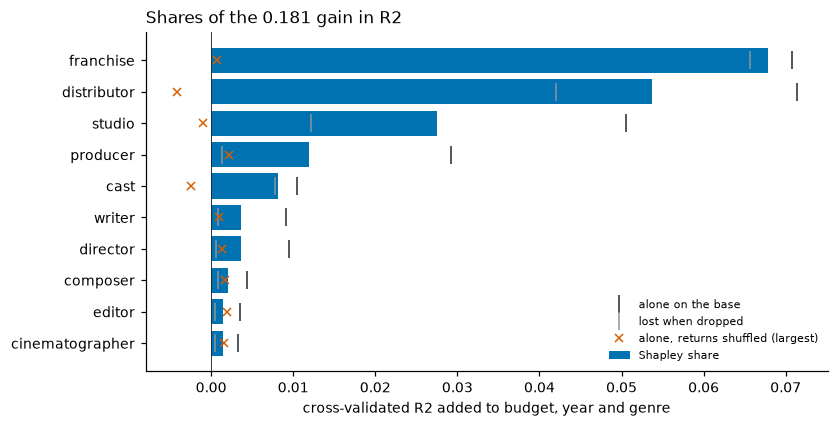

,Shapley share,alone on base,lost when dropped,"alone, shuffled max"
franchise,0.068,0.071,0.066,0.001
distributor,0.054,0.071,0.042,-0.004
studio,0.027,0.051,0.012,-0.001
producer,0.012,0.029,0.001,0.002
cast,0.008,0.010,0.008,-0.002
writer,0.004,0.009,0.001,0.001
director,0.004,0.009,0.001,0.001
composer,0.002,0.004,0.001,0.002
editor,0.001,0.004,0.000,0.002
cinematographer,0.001,0.003,0.000,0.002


In [5]:
sh, nl = S["shapley"], S["null"]
T = pd.DataFrame({"Shapley share": sh["share"], "alone on base": sh["alone_on_base"], "lost when dropped": sh["lost_when_dropped"],
                  "alone, shuffled max": nl["alone_on_base_null_max"]}).sort_values("Shapley share")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(T.index, T["Shapley share"], color=ACCENT, label="Shapley share")
ax.plot(T["alone on base"], T.index, "|", color=INK, ms=12, label="alone on the base")
ax.plot(T["lost when dropped"], T.index, "|", color=GREY, ms=12, label="lost when dropped")
ax.plot(T["alone, shuffled max"], T.index, "x", color=RED, ms=5, label="alone, returns shuffled (largest)")
ax.axvline(0, color=INK, lw=.6); ax.legend(frameon=False, fontsize=7)
ax.set_xlabel("cross-validated R2 added to budget, year and genre")
ax.set_title(f"Shares of the {sh['r2_all'] - sh['r2_base']:.3f} gain in R2", loc="left")
plt.show()
T.sort_values("Shapley share", ascending=False)

In [6]:
cov = pd.Series(S["cv"]["covariance_share"]).rename("share of variance")
cov["unexplained"] = S["cv"]["covariance_share_unexplained"]
print("Second view: cov(block's out-of-fold part, return) / var(return). The rows sum to 1.")
print(f"Sum: {cov.sum():.3f}")
cov.sort_values(ascending=False).to_frame().T

Second view: cov(block's out-of-fold part, return) / var(return). The rows sum to 1.
Sum: 1.000


,unexplained,franchise,budget,distributor,year,studio,genre,producer,cast,writer,director,composer,cinematographer,editor
share of variance,0.710,0.082,0.056,0.050,0.033,0.026,0.015,0.009,0.007,0.005,0.005,0.001,0.001,0.001


Read the two together. The first chart is about prediction: which blocks help guess a film's return. The
table is about the split of the variance itself, and its largest row by far is *unexplained*: most of the
difference between films' returns goes with nothing we can name.

## 4. Is it more than noise?

A model with thousands of effects will find something in any data. Four checks, each asking a different thing:

- **Shuffle null.** Shuffle returns among films of the same year and fit again. Years keep their level and the
  link between a film and its makers is broken, so any gain left is what the method finds in noise.
- **Split halves.** Fit the effects on two random halves of the films and correlate them. This is the check for
  individual names: a role can help predict as a block while its individual effects are too noisy to rank.
- **A second method.** The shrunk mean of each person's residuals, ignoring collaborators. If the joint model
  only reshuffled noise, the two would disagree.
- **Bootstrap.** Films resampled by franchise group; the share of effects whose 90% interval excludes zero. By
  chance alone that share would be about 10%.

Gain in cross-validated R2 over budget, year and genre: +0.181 observed; shuffled 200 times: mean -0.044, largest -0.026.


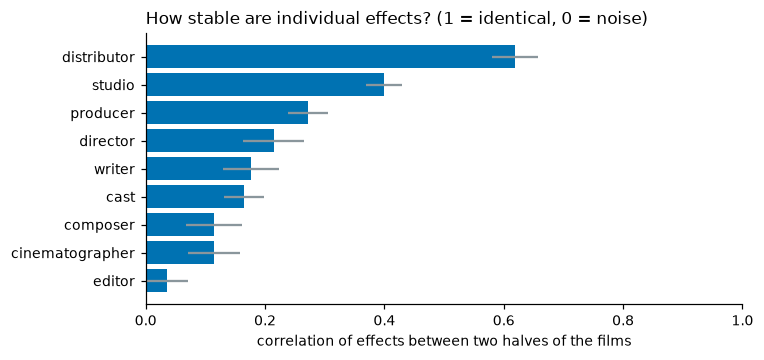

,alone on base,shuffles at or above it,split-half r,entities compared,rank agreement with one-at-a-time,share with interval off zero
director,0.009,0,0.215,171.000,0.913,0.130
cast,0.010,0,0.164,557.000,0.915,0.111
writer,0.009,0,0.176,268.000,0.897,0.082
producer,0.029,0,0.272,481.000,0.894,0.114
composer,0.004,0,0.114,187.000,0.890,0.104
cinematographer,0.003,0,0.114,250.000,0.903,0.121
editor,0.004,0,0.035,331.000,0.903,0.115
studio,0.051,0,0.400,361.000,0.904,0.118
distributor,0.071,0,0.619,137.000,0.893,0.173


In [7]:
print(f"Gain in cross-validated R2 over budget, year and genre: {nl['gain_over_base_observed']:+.3f} observed; "
      f"shuffled {nl['shuffles']} times: mean {nl['gain_over_base_null_mean']:+.3f}, largest {nl['gain_over_base_null_max']:+.3f}.")
rel = pd.DataFrame(S["split_half"]["by_role"]).T[["mean_r", "sd_r", "entities"]].astype(float)
sec = pd.DataFrame(S["second_method"]["by_role"]).T.astype(float)
chk = pd.DataFrame({"alone on base": pd.Series(sh["alone_on_base"])[ROLES],
                    "shuffles at or above it": pd.Series(nl["alone_on_base_shuffles_at_or_above_observed"])[ROLES],
                    "split-half r": rel.mean_r, "entities compared": rel.entities,
                    "rank agreement with one-at-a-time": sec.spearman,
                    "share with interval off zero": pd.Series(S["bootstrap"]["share_of_effects_with_interval_off_zero"])})
fig, ax = plt.subplots(figsize=(7, 3.2))
o = rel.mean_r.sort_values()
ax.barh(o.index, o.values, xerr=rel.sd_r[o.index], color=ACCENT, ecolor=GREY)
ax.set_xlim(0, 1); ax.set_xlabel("correlation of effects between two halves of the films")
ax.set_title("How stable are individual effects? (1 = identical, 0 = noise)", loc="left")
plt.show()
chk

The split-half column decides how far to trust a name in the next section. Where it's low, the role may
still matter as a block, but the ranking of individuals inside it is mostly noise, and a leaderboard of that role
shouldn't go in the paper.

## 5. The people and companies

The effects themselves, for those with at least five films, with 90% bootstrap intervals. `one_at_a_time` is the
second method from above; the gap between it and `effect` is what a person's collaborators account for.

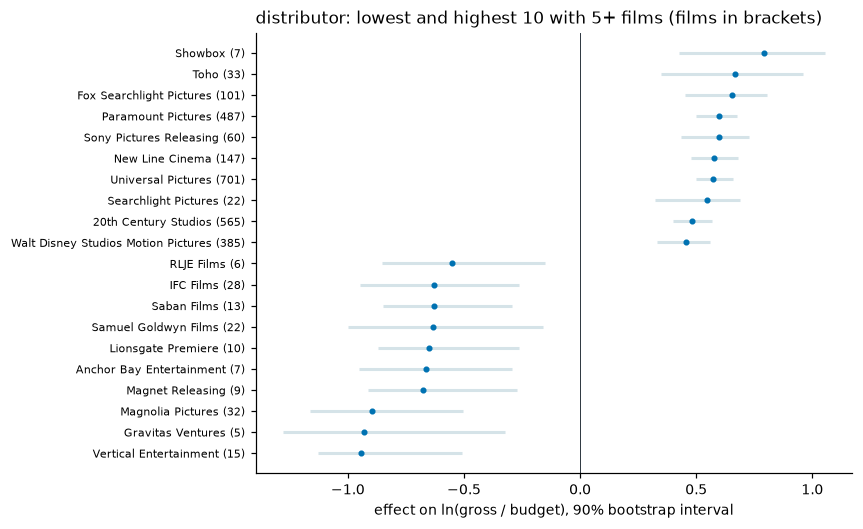

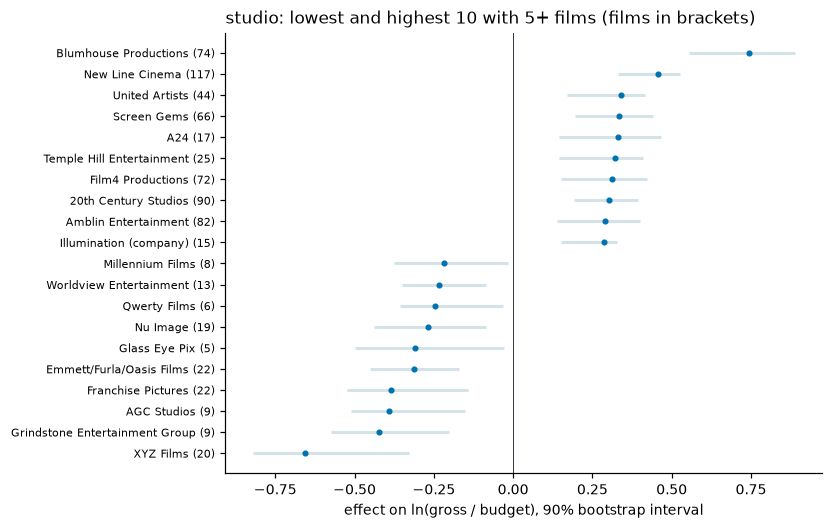

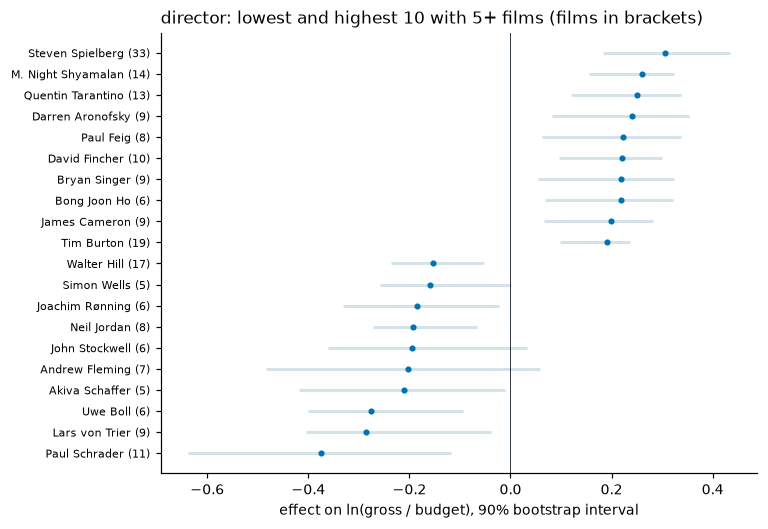

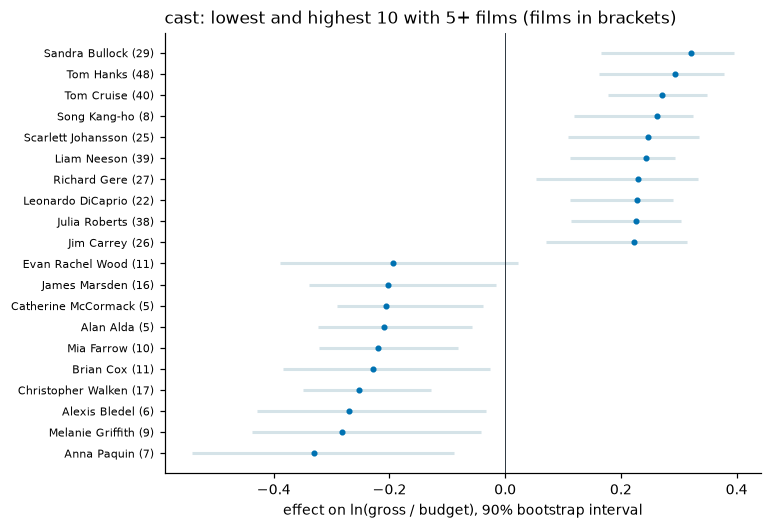

In [8]:
def board(role, k=10, min_films=5):
    d = ent[(ent.role == role) & (ent.films >= min_films)].sort_values("effect")
    d = pd.concat([d.head(k), d.tail(k)]).drop_duplicates("id")
    fig, ax = plt.subplots(figsize=(7, 0.22 * len(d) + 0.8))
    lab = d.name.fillna(d.id) + " (" + d.films.astype(str) + ")"
    ax.errorbar(d.effect, lab, xerr=[d.effect - d.lo90, d.hi90 - d.effect], fmt="o", ms=3, color=ACCENT, ecolor=LIGHT, elinewidth=2)
    ax.axvline(0, color=INK, lw=.6); ax.tick_params(axis="y", labelsize=7)
    ax.set_xlabel("effect on ln(gross / budget), 90% bootstrap interval")
    ax.set_title(f"{role}: lowest and highest {k} with {min_films}+ films (films in brackets)", loc="left")
    plt.show()

for r in ("distributor", "studio", "director", "cast"):
    board(r)

In [9]:
cols = ["role", "name", "films", "effect", "lo90", "hi90", "factor", "one_at_a_time", "usd_total"]
big = ent[ent.films >= 5]
pd.concat([big[big.role == r].nlargest(8, "usd_total") for r in ("director", "cast", "producer", "studio", "distributor")])[cols]

,role,name,films,effect,lo90,hi90,factor,one_at_a_time,usd_total
3930,director,Steven Spielberg,33,0.305,0.182,0.435,1.357,0.617,"1,429,140,434.511"
3940,director,James Cameron,9,0.199,0.066,0.283,1.221,0.233,"796,107,456.167"
3942,director,Tim Burton,19,0.190,0.097,0.236,1.209,0.212,"525,110,967.601"
3985,director,Christopher Nolan,12,0.133,0.015,0.253,1.143,0.197,"490,126,263.377"
3932,director,M. Night Shyamalan,14,0.259,0.156,0.323,1.296,0.492,"421,728,328.714"
3951,director,Roland Emmerich,13,0.163,0.067,0.226,1.177,0.161,"401,385,526.966"
4007,director,Michael Bay,14,0.120,0.033,0.151,1.127,0.200,"387,020,400.432"
3937,director,Bryan Singer,9,0.219,0.055,0.324,1.244,0.195,"378,964,800.123"
2,cast,Tom Cruise,40,0.270,0.179,0.350,1.310,0.300,"1,857,392,705.229"
1,cast,Tom Hanks,48,0.293,0.163,0.379,1.341,0.349,"1,706,438,806.144"


The distributor chart is the clearest and the easiest to misread. The companies at the bottom mostly
release films to a few cinemas or straight to video on demand, and the ones at the top are the major studios'
distribution arms. So this effect is largely the size of the release, which the model doesn't see, and not how
well a distributor does its job.

The dollar totals in the table favour people with many big, recent films, because dollars aren't adjusted for
inflation and a given effect is worth more dollars on a bigger film.

## 6. One film, split into dollars

The model works in logs, where the parts add. In dollars they multiply, and then "how many dollars is the
director worth" has no single answer: it depends on which of the other factors are already counted. The Shapley
value averages over every order. For a product of factors it has an exact formula, and the parts add up to the
film's gross minus its baseline, to the dollar. The baseline is what a film of that budget grosses at the average
multiple.

Someone with no other film in the sample has no effect to use, so their part stays in *unexplained*. Two people
who only ever work together can't be told apart, and the model gives them equal effects.

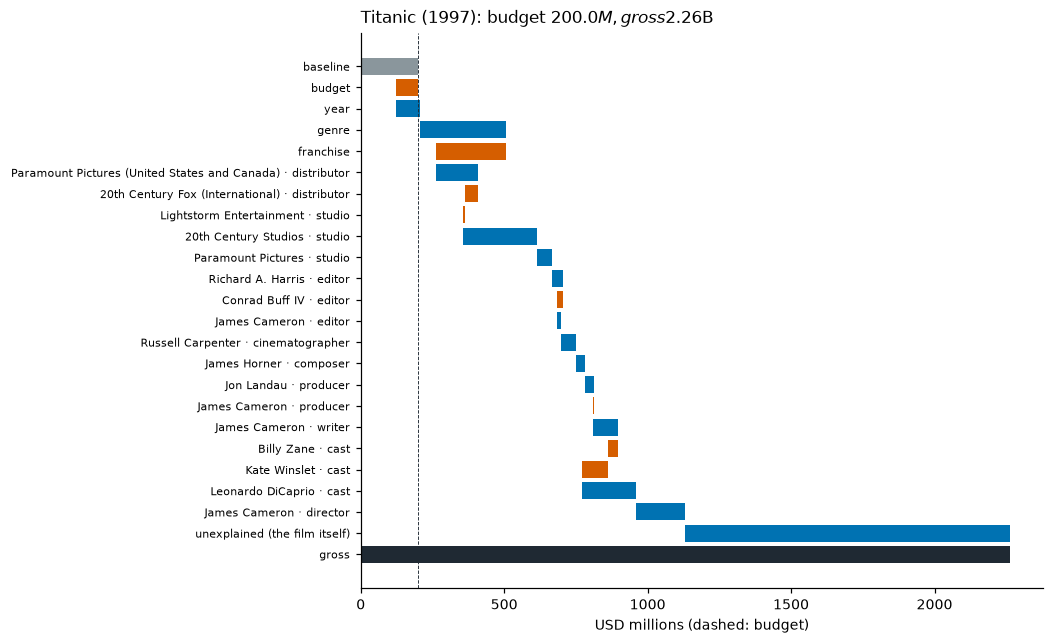

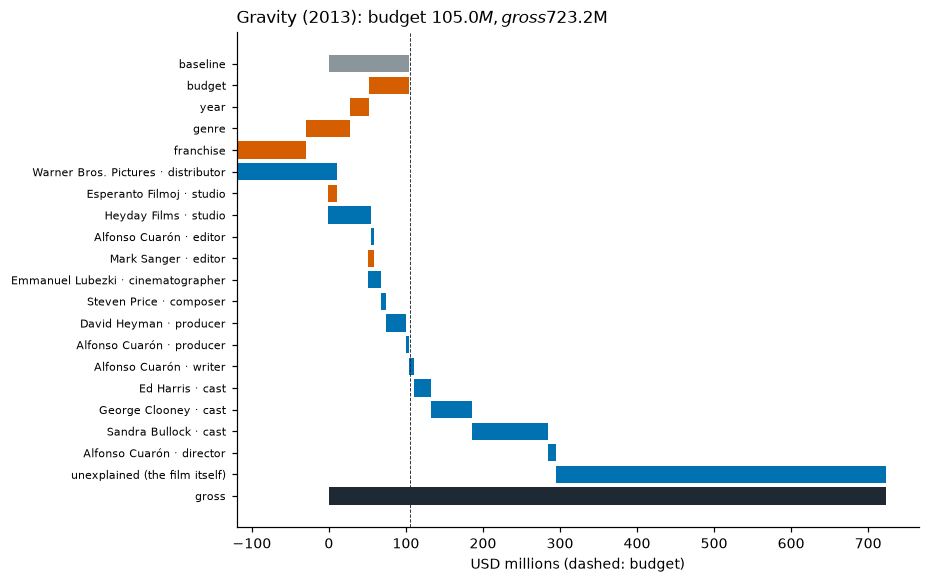

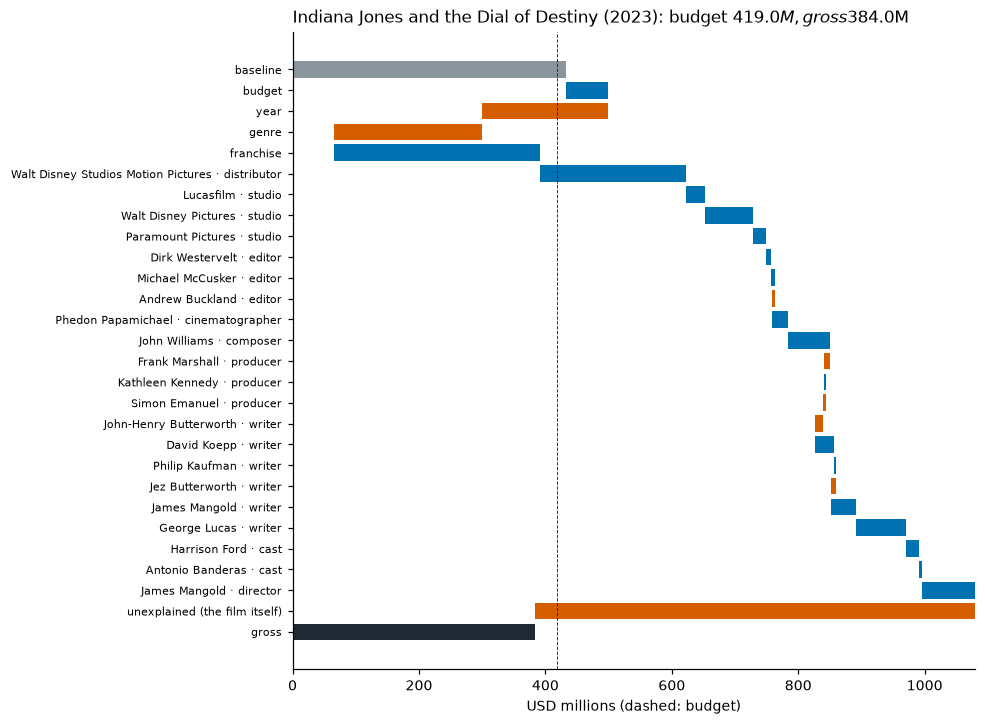

In [10]:
def waterfall(tconst, share=1.0):
    r = films[films.tconst == tconst].iloc[0]
    mine = fe[fe.tconst == tconst]
    parts = [(b, r[f"usd_{b}"]) for b in CONTROLS] + [(f"{x.name} · {x.role}", x.usd) for x in mine.itertuples(index=False)]
    parts.append(("unexplained (the film itself)", r.usd_unexplained))
    level, y = r.baseline_gross_usd * share, 0
    fig, ax = plt.subplots(figsize=(8, 0.24 * (len(parts) + 2) + 0.8))
    ax.barh(0, level / 1e6, color=GREY); labels = ["baseline"]
    for name, v in parts:
        y += 1; v *= share
        ax.barh(y, v / 1e6, left=level / 1e6, color=ACCENT if v >= 0 else RED); level += v; labels.append(name)
    ax.barh(y + 1, level / 1e6, color=INK); labels.append("gross")
    ax.axvline(r.budget_usd / 1e6, color=INK, lw=.6, ls="--")
    ax.set_yticks(range(len(labels)), labels, fontsize=7); ax.invert_yaxis(); ax.set_xlabel("USD millions (dashed: budget)")
    ax.set_title(f"{r.title} ({r.year}): budget {usd(r.budget_usd)}, gross {usd(r.gross_usd)}", loc="left")
    plt.show()
    assert abs(level - r.gross_usd * share) < 2

picks = films[films.franchise == 0].nlargest(1, "gross_usd").tconst.tolist() + films.nlargest(1, "usd_cast").tconst.tolist() \
        + films.nsmallest(1, "usd_unexplained").tconst.tolist()
for t in dict.fromkeys(picks):
    waterfall(t)

In [11]:
net, ab = pd.Series(S["dollars"]["net_by_block"]), pd.Series(S["dollars"]["absolute_by_block"])
D = pd.DataFrame({"net, USD bn": net / 1e9, "moved (sum of absolute), USD bn": ab / 1e9, "share of all dollars moved": ab / ab.sum()})
print(f"All films: gross {usd(S['dollars']['total_gross'])}, baseline {usd(S['dollars']['total_baseline_gross'])}. "
      "The net column sums to the difference.")
D.sort_values("moved (sum of absolute), USD bn", ascending=False)

All films: gross $684.28B, baseline $237.44B. The net column sums to the difference.


,"net, USD bn","moved (sum of absolute), USD bn",share of all dollars moved
unexplained,138.203,288.534,0.258
distributor,192.956,197.536,0.177
franchise,87.397,186.835,0.167
genre,-33.424,87.187,0.078
studio,65.758,79.010,0.071
budget,-51.795,64.049,0.057
year,-29.335,63.223,0.057
cast,22.743,43.809,0.039
writer,9.874,26.122,0.023
director,13.759,25.629,0.023


### In real dollars

A dollar of gross in 1977 isn't a dollar in 2019. The US consumer price index (BLS CPI-U, yearly means in
`data/cpi_us_annual.csv`) converts each film's dollars to those of the latest year in the file. This part is real
data, with limits: budgets are spent a year or two before release and we use the release year, and a worldwide
gross isn't all earned in the US. The model itself doesn't need it, since it works with gross ÷ budget and has
year terms.

In [12]:
cpi = pd.read_csv(REPO / "data" / "cpi_us_annual.csv").set_index("year").cpi
base_year = int(cpi.index.max())
k = films.year.map(cpi[base_year] / cpi)
U = [c for c in films.columns if c.startswith("usd_")]
real, nom = films[U].mul(k, axis=0), films[U]
R = pd.DataFrame({"nominal share of dollars moved": nom.abs().sum() / nom.abs().sum().sum(),
                  f"share in {base_year} dollars": real.abs().sum() / real.abs().sum().sum()})
R.index = [c[4:] for c in R.index]
est_n, est_r = 0.5 * films.gross_usd - films.budget_usd, (0.5 * films.gross_usd - films.budget_usd) * k
print(f"A 1975 dollar is {cpi[base_year] / cpi[1975]:.2f} {base_year} dollars; a 2000 dollar {cpi[base_year] / cpi[2000]:.2f}.")
print(f"50% of gross minus budget, all films: {usd(est_n.sum())} nominal, {usd(est_r.sum())} in {base_year} dollars.")
print(f"Films in both top-25 lists by that measure: {len(set(est_n.nlargest(25).index) & set(est_r.nlargest(25).index))} of 25.")
top = films.assign(real_gross=films.gross_usd * k, real_est=est_r).nlargest(10, "real_est")[["title", "year", "gross_usd", "real_gross", "real_est"]]
display(top.style.format({"gross_usd": usd, "real_gross": usd, "real_est": usd}).hide(axis="index"))
R.sort_values(f"share in {base_year} dollars", ascending=False)

A 1975 dollar is 5.98 2025 dollars; a 2000 dollar 1.87.
50% of gross minus budget, all films: $106.11B nominal, $187.48B in 2025 dollars.
Films in both top-25 lists by that measure: 16 of 25.


title,year,gross_usd,real_gross,real_est
Star Wars: Episode IV - A New Hope,1977,$775.4M,$4.12B,$2.00B
Titanic,1997,$2.26B,$4.54B,$1.87B
Avatar,2009,$2.92B,$4.39B,$1.84B
Jaws,1975,$495.0M,$2.96B,$1.43B
Avengers: Endgame,2019,$2.94B,$3.70B,$1.38B
E.T. the Extra-Terrestrial,1982,$797.3M,$2.66B,$1.29B
Jurassic Park,1993,$1.06B,$2.36B,$1.05B
The Lion King,1994,$979.0M,$2.13B,$965.4M
Star Wars: Episode V - The Empire Strikes Back,1980,$549.5M,$2.15B,$954.2M
Grease,1978,$396.3M,$1.96B,$948.3M


,nominal share of dollars moved,share in 2025 dollars
unexplained,0.258,0.262
distributor,0.177,0.174
franchise,0.167,0.164
genre,0.078,0.077
studio,0.071,0.067
year,0.057,0.063
budget,0.057,0.059
cast,0.039,0.039
director,0.023,0.023
writer,0.023,0.023


The three films are picked by rule, not by taste: the highest-grossing film outside a franchise, the film
where the cast adds the most dollars, and the film with the largest unexplained loss.

## 7. What could be known before release

Everything above uses a person's other films from any year, including later ones. That's the right question for
"how do this director's films do", and the wrong one for prediction. The strict version fits the effects on films
from earlier years only, year by year. Both versions of every film's split are saved in `films.csv` (`ln_*` and
`fwd_*`), so whichever fits the paper's question can be used.

In [13]:
fw = S["forward"]
print(f"Films from {fw['from_year']} on ({fw['films']:,}), effects from earlier years only: R2 {fw['r2_full']:.3f}, "
      f"against {fw['r2_base']:.3f} for budget, year and genre.")
print(f"Rank correlation within release year: {fw['spearman_within_year_full']:+.3f} against {fw['spearman_within_year_base']:+.3f}.")
ok = films.predicted_forward.notna()
both = pd.DataFrame({r: [spearmanr(films.loc[ok, f"ln_{r}"], films.loc[ok, f"fwd_{r}"]).statistic] for r in ROLES}, index=["rank agreement, out of fold vs earlier years"])
both

Films from 1990 on (5,677), effects from earlier years only: R2 0.219, against 0.059 for budget, year and genre.
Rank correlation within release year: +0.471 against +0.240.


,director,cast,writer,producer,composer,cinematographer,editor,studio,distributor
"rank agreement, out of fold vs earlier years",0.649,0.683,0.602,0.682,0.682,0.674,0.642,0.725,0.774


## 8. Summary

Printed from the cells above, so it changes with the data.

In [14]:
order = pd.Series(sh["share"]).sort_values(ascending=False)
stable = rel.mean_r.sort_values(ascending=False)
print(f"1. Measures: at a 50% share, {S['measures']['scenarios']['0.5']['share_of_films_above_break_even']:.0%} of films clear break-even "
      f"and the top tenth earns {S['measures']['scenarios']['0.5']['share_of_all_gains_from_top_decile_of_films']:.0%} of all gains; "
      f"only {S['measures']['scenarios']['0.5']['top_decile_overlap_with_multiple']:.0%} of the top tenth by multiple is in the top tenth by dollars.")
print(f"2. Model: cross-validated R2 {S['cv']['r2_base']:.3f} -> {S['cv']['r2_full']:.3f} when franchise, people and companies are added; "
      f"{S['cv']['covariance_share_unexplained']:.0%} of the variance stays unexplained.")
print("3. Shares of the gain: " + ", ".join(f"{b} {v:.3f}" for b, v in order.items()) + ".")
print(f"4. Shuffled returns: gain at most {nl['gain_over_base_null_max']:+.3f} against {nl['gain_over_base_observed']:+.3f} observed. "
      "Split-half r: " + ", ".join(f"{b} {v:.2f}" for b, v in stable.items()) + ".")
boot = pd.Series(S["bootstrap"]["share_of_effects_with_interval_off_zero"])
print("   Share of effects whose 90% interval excludes zero (10% expected by chance): " + ", ".join(f"{b} {v:.0%}" for b, v in boot.sort_values(ascending=False).items()) + ".")
print(f"5. Earlier years only: R2 {fw['r2_full']:.3f} against {fw['r2_base']:.3f}.")

1. Measures: at a 50% share, 51% of films clear break-even and the top tenth earns 69% of all gains; only 37% of the top tenth by multiple is in the top tenth by dollars.
2. Model: cross-validated R2 0.115 -> 0.299 when franchise, people and companies are added; 71% of the variance stays unexplained.
3. Shares of the gain: franchise 0.068, distributor 0.054, studio 0.027, producer 0.012, cast 0.008, writer 0.004, director 0.004, composer 0.002, editor 0.001, cinematographer 0.001.
4. Shuffled returns: gain at most -0.026 against +0.181 observed. Split-half r: distributor 0.62, studio 0.40, producer 0.27, director 0.21, writer 0.18, cast 0.16, composer 0.11, cinematographer 0.11, editor 0.04.
   Share of effects whose 90% interval excludes zero (10% expected by chance): distributor 17%, director 13%, cinematographer 12%, studio 12%, editor 12%, producer 11%, cast 11%, composer 10%, writer 8%.
5. Earlier years only: R2 0.219 against 0.059.
